# **The ISA book**



This notebook concerns the (current) final book of the ISA automatic trading system, that being the combination each other part, alongside comparing portfolio optimisation techniques across the book. Most of the book was built in-sample on 2001-2026, so backtested Sharpe is higher than estimated Sharpe.

## Imports

In [9]:
import sys
from pathlib import Path
import numpy as np

here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## The book vs Major indices (2001 Onwards)

The main aim of this system was to outperform standard investing methods, i.e buy-and-hold a major stock index. By 'outperform', that is by Sharpe, total final equity, and hopefully max drawdown. This was completed, and is show on the plot below. This is not a perfect benchmark, but just a showcase of the system against what it was hoped to beat.

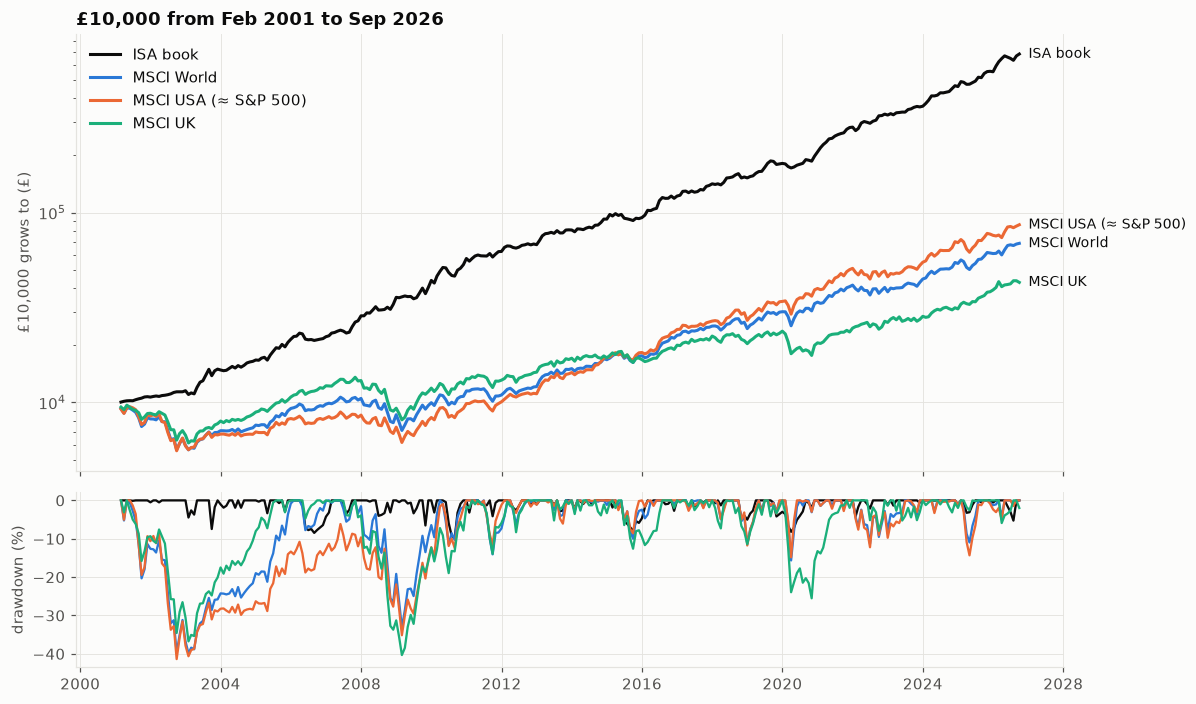

,CAGR %,Sharpe,volatility %,max drawdown %,£10k becomes
ISA book,17.900,1.480,9.870,-9.940,"684,128.670"
MSCI World,7.810,0.450,13.660,-39.910,"68,864.430"
MSCI USA (≈ S&P 500),8.760,0.490,14.360,-41.370,"86,302.890"
MSCI UK,5.840,0.320,13.150,-40.310,"42,887.750"


In [10]:
b = sp.table("benchmarks_monthly.csv").set_index("month")
b.index = pd.PeriodIndex(b.index, freq="M").to_timestamp("M")
series = {"ISA book": d["book"],
          "MSCI World": b["MSCI World"].reindex(d.index),
          "MSCI USA (≈ S&P 500)": b["MSCI USA"].reindex(d.index),
          "MSCI UK": b["MSCI UK"].reindex(d.index)}
colors = {"ISA book": sp.COLORS["book"], "MSCI World": "#2a78d6", "MSCI USA (≈ S&P 500)": "#eb6834", "MSCI UK": "#1baf7a"}
sp.curves(series, colors, f"£10,000 from {d.index[0]:%b %Y} to {d.index[-1]:%b %Y}")

def summary(r):
    x = r - d["cash"]
    w = (1 + r).cumprod()
    return pd.Series({"CAGR %": 100 * (w.iloc[-1] ** (12 / len(r)) - 1),
                      "Sharpe": x.mean() / x.std() * 12 ** 0.5,
                      "volatility %": 100 * r.std() * 12 ** 0.5,
                      "max drawdown %": (100 * (w / w.cummax() - 1)).min(),
                      "£10k becomes": 10_000 * w.iloc[-1]})

pd.DataFrame({k: summary(v) for k, v in series.items()}).T.round(2)

The statistics align with the plot, that the book does infact outperform these 3 major stock indices.

## The book since 1979

As stated at the start, the book was built in-sample on 2001-2026. I have now extended the history backwards to history it had not seen before (February 1979 - January 2001). An index or futures history is used for an ETF which did not exist at that point. The main thing to note is that the core has no usable history before 2001, so for that period of time a standard world equity is used with the same rebound/defensive rules as before. "Core path" denotes "Core + rebound + defensive".

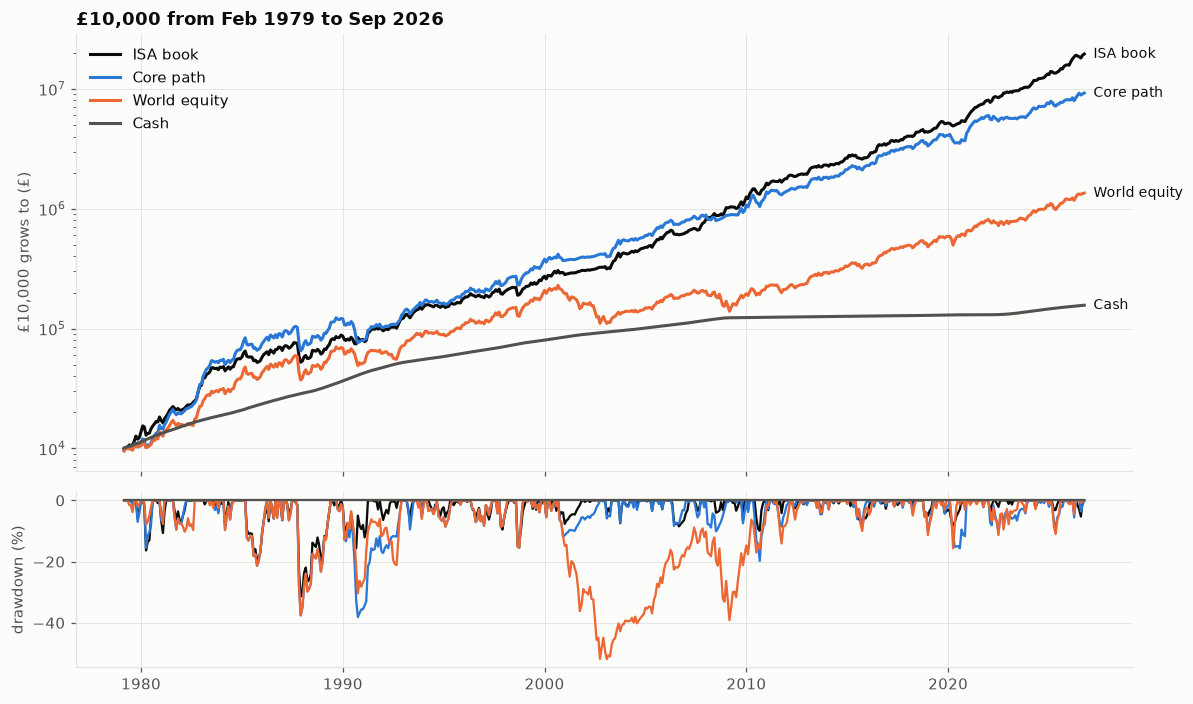

In [11]:
L = sp.table("book_long_monthly.csv").set_index("month")
L.index = pd.PeriodIndex(L.index, freq="M").to_timestamp("M")
long_series = {"ISA book": L["book"], "Core path": L["core_path"], "World equity": L["world_equity"], "Cash": L["cash"]}
long_colors = {"ISA book": sp.COLORS["book"], "Core path": sp.COLORS["core"], "World equity": "#eb6834", "Cash": sp.MUTED}
sp.curves(long_series, long_colors, f"£10,000 from {L.index[0]:%b %Y} to {L.index[-1]:%b %Y}")

Sharpe is measured as annual returns above the interest rate at the time. The economic climate looked significantly different pre-2000, with rates averaging ~12.6% p.a, compared with ~2.4% since. This makes results look seemingly worse without any real justification, so a standard return/volatility column is included as a comparison metric between the two eras.

In [12]:
def period_stats(x, col):
    r, n = x[col], len(x)
    w = (1 + r).cumprod()
    vol = r.std() * np.sqrt(12)
    ex = r - x["cash"]
    return {"CAGR %": 100 * ((1 + r).prod() ** (12 / n) - 1), "vol %": 100 * vol,
            "Sharpe over cash": ex.mean() / ex.std() * np.sqrt(12), "return / vol": r.mean() * 12 / vol,
            "max drawdown %": 100 * (w / w.cummax() - 1).min(),
            "cash rate %": 100 * ((1 + x["cash"]).prod() ** (12 / n) - 1)}

periods = {"1979–2026": ("1979", "2026"), "1979–1989": ("1979", "1989"),
           "1990–2000": ("1990", "2001-01"), "2001–2026": ("2001-02", "2026")}
rows = {(p, name): period_stats(L.loc[a:b], col) for p, (a, b) in periods.items()
        for name, col in [("ISA book", "book"), ("Core path", "core_path"), ("World equity", "world_equity")]}
pd.DataFrame(rows).T.round(2)

CAGR %  vol %  Sharpe over cash  return / vol  max drawdown %  cash rate %
1979–2026 ISA book      17.230 13.320             0.830         1.270         -31.370        5.940
          Core path     15.400 15.520             0.630         1.010         -38.120        5.940
          World equity  10.840 15.830             0.370         0.730         -51.850        5.940
1979–1989 ISA book      21.850 19.080             0.510         1.140         -31.370       12.610
          Core path     25.610 21.460             0.620         1.180         -37.560       12.610
          World equity  19.330 20.120             0.390         0.990         -37.560       12.610
1990–2000 ISA book      11.370 13.370             0.300         0.880         -14.290        7.970
          Core path     10.730 16.010             0.240         0.720         -33.450        7.970
          World equity   9.910 15.610             0.190         0.690         -27.800        7.970
2001–2026 ISA book      17.900  9.870             1.480         1.730          -9.940        2.390
          Core path     13.320 11.770             0.920         1.130         -19.770        2.390
          World equity   7.810 13.660             0.450         0.620         -39.910        2.390

In 1979-1989, we see that the sleeves reduce return from the core path, alongside volatility and reducing drawdowns. This reduction, after further inspection, is almost entirely due to one asset having a terrible bear period during this time, and is not a statement about all sleeves together. Its also seen that 1990-2000 was not the best period for equities, with all Sharpe's pitifully low due to high interest rates, and high volatilities carrying over from the preceding decade. The sleeves do contribute in this decade though, improving both CAGR and Sharpe, implying that the 1980s were just a weak period, primarily because of one asset. For these reasons, a forward Sharpe of 0.9-1.3 is estimated going forward, the lower end if the previous regime of higher interest rates returns (and the system does not change accordingly), and the higher end if the current regime stays relatively consistent.

## Building the book part by part

The book is a combination of the 5 other folders in the showcase, that being a core holding, a defensive basket for tough economic periods, a rebound basket held just after such tough economic period alongside 'sleeves' and 'overlays' which contain assets which are held under certain market conditions and timings. The following table shows how each component adds to the final product

In [13]:
t = sp.table("layers_stats.csv")
t = t[t["window"].str.startswith("full")].set_index("layers")
t[["cagr_pct", "sharpe", "max_drawdown_pct", "final_gbp_from_10k"]].round(2)

,cagr_pct,sharpe,max_drawdown_pct,final_gbp_from_10k
layers,,,,
core,8.690,0.560,-35.710,"84,969.960"
core + defensive,10.770,0.850,-16.020,"138,234.570"
core + defensive + rebound,13.320,0.920,-19.770,"247,424.290"
core + defensive + rebound + overlay,14.350,1.000,-19.770,"312,697.020"
book (all five parts),17.900,1.480,-9.940,"684,128.670"


## Each part's contribution

The below table shows how much each part contributes to the portfolio.

In [14]:
t = sp.table("parts_stats.csv")
t = t[t["window"].str.startswith("full")].set_index("part")
t[["mean_pp_per_year", "vol_pp_per_year", "sharpe_of_contribution", "correlation_with_core"]].round(2)

,mean_pp_per_year,vol_pp_per_year,sharpe_of_contribution,correlation_with_core
part,,,,
core,9.080,11.920,0.760,1.000
defensive,1.690,7.240,0.230,-0.560
rebound,2.480,4.800,0.520,0.160
overlay,0.920,1.970,0.470,-0.080
sleeves,2.890,7.170,0.400,-0.320


See that (unsurprisingly) the core and sleeves, alongside the rebound basket are the biggest contributors to the book. The biggest thing to note here is that each basket is uncorrelated with the core, leading to a wide range of diverse return sources, which is something I was really keen for.

## Weighting methods

The core path is fixed. I tested various weighting mathods to decide allocations to each sleeve/overlay. The fixed method, being scaled shrinkage weights by a constant, with some caps to sleeve weight and a floor to the core, was chosen on an older version of the system, and was retained as being the 'method to beat'. The below table uses all fund histories, and hence begins in 2006.

In [15]:
t = sp.table("methods_shipped_config.csv").head(6).set_index("method_name")
base = t.iloc[0]
diff = pd.DataFrame({"floor": t["floor"], "cap": t["cap"],
                     "Δ Sharpe vs shipped": t["dsharpe_vs_shipped"],
                     "90% interval": [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(t["dsharpe_lo_90"], t["dsharpe_hi_90"])],
                     "Δ CAGR (pp)": t["cagr_pct"] - base["cagr_pct"],
                     "Δ max drawdown (pp, + = shallower)": t["max_drawdown_pct"] - base["max_drawdown_pct"]})
diff.round(3)

,floor,cap,Δ Sharpe vs shipped,90% interval,Δ CAGR (pp),"Δ max drawdown (pp, + = shallower)"
method_name,,,,,,
pro rata at own weights x k (shipped),0.300,0.200,0.000,"[+0.00, +0.00]",0.000,0.000
equal risk contribution,0.200,0.200,-0.049,"[-0.20, +0.11]",-0.373,0.590
inverse volatility,0.000,0.200,-0.056,"[-0.20, +0.10]",-0.698,0.361
equal risk contribution,0.300,0.200,-0.070,"[-0.21, +0.08]",-0.594,0.230
"tangency, Bayes-Stein means, Ledoit-Wolf covariance",0.200,0.200,-0.074,"[-0.21, +0.06]",-1.047,-0.544
"hierarchical Bayes means, tangency",0.200,0.200,-0.077,"[-0.21, +0.06]",-1.057,-0.321


The fixed rule beats the other best performing portfolio optimisation methods on CAGR and Sharpe, but the interval for Sharpe does include zero and hence is not significant. The best performing equal risk contribution method had a shallower drawdown too. Due to the longer history, I decided to fix this rule, and then test backwards with other methods. The natural alternative is risk parity, due to it only using volatility and covariance, so it reduces the ability to overfit to data.

In [16]:
rp = sp.table("risk_parity_long.csv")
rp["90% interval"] = [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(rp["dsharpe_lo_90"], rp["dsharpe_hi_90"])]
rp = rp.rename(columns={"dsharpe_vs_shipped": "Δ Sharpe vs shipped", "dcagr_pp": "Δ CAGR (pp)", "dmdd_pp": "Δ max drawdown (pp, + = shallower)"})
rp.set_index(["method", "window"])[["Δ Sharpe vs shipped", "90% interval", "Δ CAGR (pp)", "Δ max drawdown (pp, + = shallower)"]].round(3)

Δ Sharpe vs shipped    90% interval  Δ CAGR (pp)  Δ max drawdown (pp, + = shallower)
method                                    window                                                                                         
risk parity (forecast covariance, capped) 1979-2001               -0.017  [-0.14, +0.09]       -0.312                               0.043
                                          2001-2026               -0.029  [-0.13, +0.08]       -1.022                              -2.197
inverse volatility (capped)               1979-2001               -0.021  [-0.15, +0.09]       -0.387                               0.043
                                          2001-2026               -0.035  [-0.13, +0.07]       -1.075                              -2.290

Risk parity was slightly worse than the fixed rule on both periods, as was inverse volatility, in both CAGR, max drawdown and Sharpe, although the Sharpe interval contains zero, so is not significant. Hence the original rule is kept.